# ShadowFox Python Internship — Cricket Fielding Analysis

## Task
Analyze fielding performance for **three players** from a T20 innings using the supplied IPL sample dataset.

### Selected players
- Rilee russouw
- Phil Salt
- Yash Dhull

The supplied sample workbook contains both ball-level fielding events and a performance matrix. This notebook uses the provided matrix for the performance-score analysis and the provided event data for basic event inspection.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

events = pd.read_csv("../data/ipl_fielding_events.csv")
performance = pd.read_csv("../data/ipl_performance_matrix.csv")

print("Fielding events:", events.shape)
print("Performance matrix:", performance.shape)
display(events.head())
display(performance)


Fielding events: (12, 12)
Performance matrix: (7, 11)


,Match No.,Innings,Teams,Player Name,BallCount,Position,Pick,Throw,Runs,Overcount,Venue,Stadium
0,IPL2367,1,Delhi Capitals,Rilee russouw,0.1,Short mid wicket,n,NaN,1.0,1,Delhi,Arun Jaitly Stadium
1,IPL2367,1,Delhi Capitals,Phil Salt,0.2,wicket keeper,Y,Y,NaN,1,Delhi,Arun Jaitly Stadium
2,IPL2367,1,Delhi Capitals,Yash Dhull,0.3,covers,Y,Y,NaN,1,Delhi,Arun Jaitly Stadium
3,IPL2367,1,Delhi Capitals,Axer Patel,0.4,point,Y,Y,NaN,1,Delhi,Arun Jaitly Stadium
4,IPL2367,1,Delhi Capitals,NaN,0.5,NaN,NaN,NaN,NaN,1,Delhi,Arun Jaitly Stadium


,Player Name,Clean Picks (CP),Good Throws (GT),Catches (C),Dropped Catches (DC),Stumpings (S),Run Outs (RO),Missed Run Outs (MR),Direct Hits (DH),Runs Saved (RS),Performance Score (PS)
0,Rilee russouw,2,1,1,0,0,0,0,1,2,10
1,Phil Salt,1,2,0,1,0,1,0,0,-1,2
2,Yash Dhull,3,1,2,0,0,0,1,0,3,11
3,Axer Patel,2,3,1,0,1,0,0,0,0,11
4,Lalit yadav,1,2,1,0,0,0,0,1,-2,6
5,Aman Khan,4,1,0,0,0,1,0,0,1,9
6,Kuldeep yadav,3,0,1,1,0,0,0,1,4,9


## Research Questions

1. What are the performance-score components for the three selected players?
2. How do their fielding action counts compare?
3. How do runs saved/conceded contribute to the overall performance score?


In [2]:
selected_players = ["Rilee russouw", "Phil Salt", "Yash Dhull"]
selected_df = performance[performance["Player Name"].isin(selected_players)].copy()

selected_df


,Player Name,Clean Picks (CP),Good Throws (GT),Catches (C),Dropped Catches (DC),Stumpings (S),Run Outs (RO),Missed Run Outs (MR),Direct Hits (DH),Runs Saved (RS),Performance Score (PS)
0,Rilee russouw,2,1,1,0,0,0,0,1,2,10
1,Phil Salt,1,2,0,1,0,1,0,0,-1,2
2,Yash Dhull,3,1,2,0,0,0,1,0,3,11


## Verify the Performance Score

The supplied task defines the score as:

**PS = CP×1 + GT×1 + C×3 + DC×(-3) + ST×3 + RO×3 + MR×(-2) + DH×2 + RS**

These weights are taken directly from the supplied sample workbook.


In [3]:
weights = {
    "Clean Picks (CP)": 1,
    "Good Throws (GT)": 1,
    "Catches (C)": 3,
    "Dropped Catches (DC)": -3,
    "Stumpings (S)": 3,
    "Run Outs (RO)": 3,
    "Missed Run Outs (MR)": -2,
    "Direct Hits (DH)": 2,
    "Runs Saved (RS)": 1,
}

def calculate_score(row):
    return sum(row[col] * weight for col, weight in weights.items())

selected_df["Calculated PS"] = selected_df.apply(calculate_score, axis=1)
selected_df[["Player Name", "Performance Score (PS)", "Calculated PS"]]


,Player Name,Performance Score (PS),Calculated PS
0,Rilee russouw,10,10
1,Phil Salt,2,2
2,Yash Dhull,11,11


## Performance Score Comparison

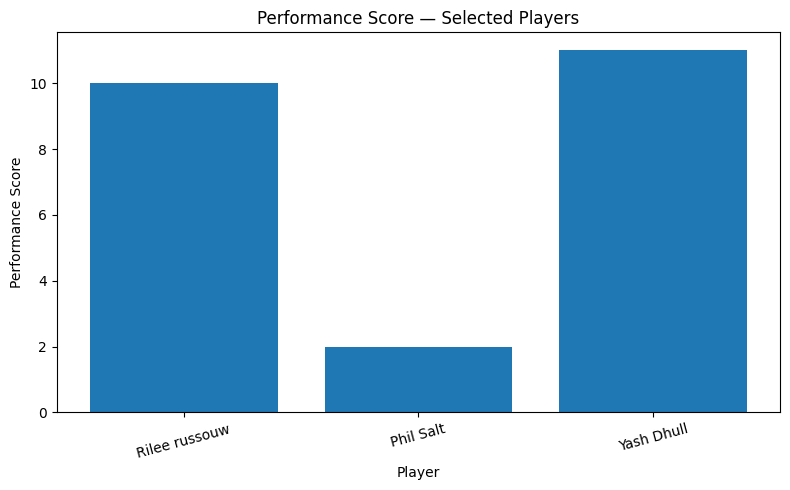

In [4]:
plt.figure(figsize=(8, 5))
plt.bar(selected_df["Player Name"], selected_df["Calculated PS"])
plt.title("Performance Score — Selected Players")
plt.xlabel("Player")
plt.ylabel("Performance Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Fielding Action Counts

,Clean Picks (CP),Good Throws (GT),Catches (C),Dropped Catches (DC),Stumpings (S),Run Outs (RO),Missed Run Outs (MR),Direct Hits (DH)
Player Name,,,,,,,,
Rilee russouw,2,1,1,0,0,0,0,1
Phil Salt,1,2,0,1,0,1,0,0
Yash Dhull,3,1,2,0,0,0,1,0


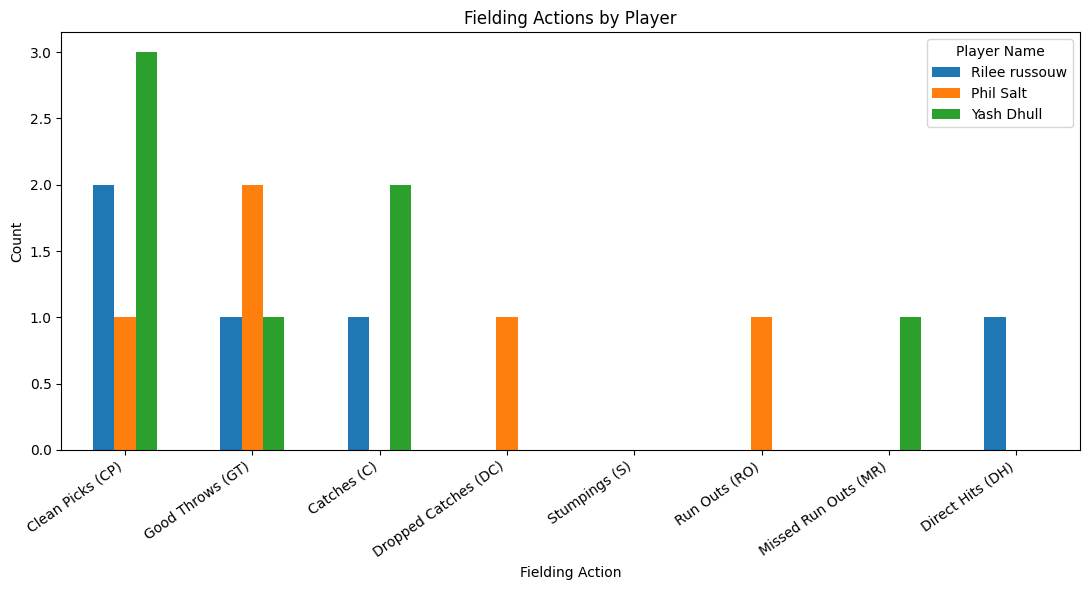

In [5]:
action_cols = [
    "Clean Picks (CP)", "Good Throws (GT)", "Catches (C)",
    "Dropped Catches (DC)", "Stumpings (S)", "Run Outs (RO)",
    "Missed Run Outs (MR)", "Direct Hits (DH)"
]

action_data = selected_df.set_index("Player Name")[action_cols]
display(action_data)

action_data.T.plot(kind="bar", figsize=(11, 6))
plt.title("Fielding Actions by Player")
plt.xlabel("Fielding Action")
plt.ylabel("Count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## Runs Saved / Conceded

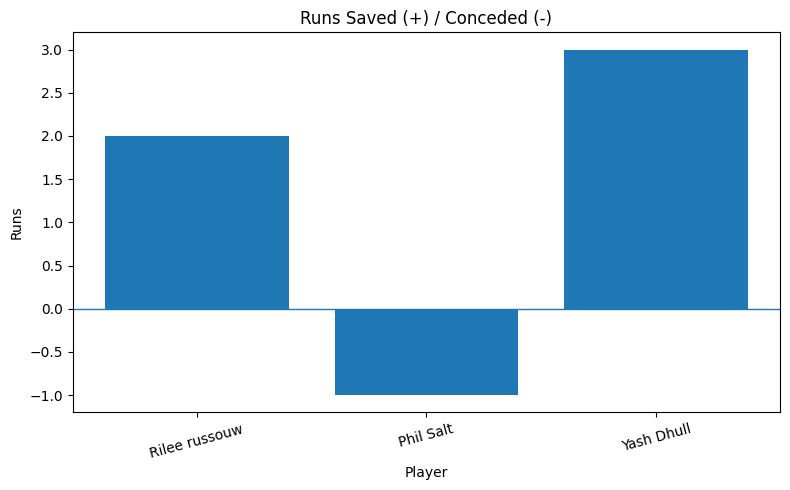

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(selected_df["Player Name"], selected_df["Runs Saved (RS)"])
plt.axhline(0, linewidth=1)
plt.title("Runs Saved (+) / Conceded (-)")
plt.xlabel("Player")
plt.ylabel("Runs")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Ball-Level Event Sample

The supplied workbook contains ball-level records for the sample innings. The table below shows events involving the three selected players where records are available in the provided event sample.


In [7]:
selected_events = events[events["Player Name"].isin(selected_players)].copy()
display(selected_events)


,Match No.,Innings,Teams,Player Name,BallCount,Position,Pick,Throw,Runs,Overcount,Venue,Stadium
0,IPL2367,1,Delhi Capitals,Rilee russouw,0.1,Short mid wicket,n,NaN,1.0,1,Delhi,Arun Jaitly Stadium
1,IPL2367,1,Delhi Capitals,Phil Salt,0.2,wicket keeper,Y,Y,NaN,1,Delhi,Arun Jaitly Stadium
2,IPL2367,1,Delhi Capitals,Yash Dhull,0.3,covers,Y,Y,NaN,1,Delhi,Arun Jaitly Stadium


## Findings

- The three selected players have different combinations of clean picks, throws, catches, run-outs, direct hits and runs saved/conceded.
- The performance score is a weighted metric, so high-value actions such as catches, run-outs, stumpings and direct hits affect the score more than a clean pick or good throw.
- Dropped catches and missed run-outs carry negative weights in the supplied scoring system.
- The supplied sample data should be treated as the source dataset for this internship submission; no missing ball-level events are invented here.


## Conclusion

This analysis demonstrates data loading, filtering, score calculation, comparison, and visualization using Python, Pandas, Matplotlib and Seaborn. The notebook can be extended with a complete ball-by-ball dataset for a larger match analysis.
